# Sistema de Recomendacion KNN

Lucho May | 2024 <br>
Les passants by Zaz

### Descripcion KNN

KNN (K-Nearest Neighbors o K vecinos más cercanos) es un algoritmo de aprendizaje automático que se utiliza en sistemas de recomendación para sugerir productos, películas, música u otros elementos según las similitudes entre usuarios o elementos.

Su objetivo es identificar usuarios con gustos similares o elementos parecidos para generar recomendaciones personalizadas.

- Como funciona? <br>
El funcionamiento de un sistema de recomendación con KNN se divide en cuatro etapas:

    - Recopilación de datos: se obtiene información sobre las preferencias, calificaciones, compras o interacciones de los usuarios.
    - Cálculo de similitudes: se comparan los usuarios o elementos mediante métricas de distancia o similitud.
    - Selección de vecinos: se identifican los K usuarios o elementos más similares.
    - Generación de recomendaciones: se recomiendan elementos que podrían interesarle al usuario, basándose en las preferencias de sus vecinos.


- Metricas <br>
Estas métricas permiten determinar qué tan parecidos son dos usuarios o elementos.

    - Distancia euclidiana: mide la distancia entre dos vectores. Cuanto menor sea el valor, más cercanos serán.
    - Similitud del coseno: mide el ángulo entre dos vectores de preferencias. Un valor cercano a 1 indica una alta similitud.
    - Correlación de Pearson: mide la relación entre las calificaciones de dos usuarios. Un valor cercano a 1 indica que sus preferencias tienden a variar de manera similar.
    - Distancia Manhattan: calcula la suma de las diferencias absolutas entre los valores de dos vectores.

La elección de la métrica depende del tipo de datos y del problema que se desea resolver.

- Metricas Evaluacion <br>

| Métrica | Descripción |
| :--- | :--- |
| **MAE (Error Absoluto Medio)** | Calcula el promedio de las diferencias absolutas entre las calificaciones reales y las predichas. Un valor menor indica mejores predicciones. |
| **RMSE (Raíz del Error Cuadrático Medio)** | Mide el error de las predicciones y penaliza más los errores grandes. Un valor menor es mejor. |
| **Precisión (Precision)** | Mide qué proporción de los elementos recomendados son relevantes para el usuario. |
| **Recall (Exhaustividad)** | Mide qué proporción de todos los elementos relevantes fue recomendada. |
| **F1-score** | Combina precisión y recall en una única medida, utilizando su media armónica. |


- Metricas Importantes <br>

    - **Para predecir calificaciones:** se utilizan principalmente MAE y RMSE.
    - **Para evaluar listas de películas, productos o música recomendados:** se utilizan Precision, Recall y F1-score.
    - **Para identificar usuarios o elementos similares:** se utilizan la similitud del coseno, la correlación de Pearson y las métricas de distancia.


- La importancia K

El parámetro **K** representa la cantidad de vecinos que el algoritmo utiliza para generar una recomendación. <br>

- Un valor de **K muy pequeño** puede producir recomendaciones demasiado sensibles a usuarios individuales.
- Un valor de **K muy grande** puede incluir usuarios con preferencias poco relacionadas.
- El valor adecuado se determina mediante pruebas y validación con los datos disponibles. <br>
<br>

- Ventajas
    - Es sencillo de comprender e implementar.
    - Permite generar recomendaciones personalizadas.
    - Puede trabajar con diferentes tipos de preferencias y calificaciones.
    - No requiere entrenar un modelo complejo.

- Desventajas
    - Puede ser lento cuando existen grandes cantidades de usuarios o elementos.
    - Su rendimiento depende de la métrica de similitud y del valor K.
    - Puede tener dificultades cuando hay poca información sobre usuarios o elementos nuevos, un problema conocido como *arranque en frío* (cold start).
    - Puede verse afectado por datos incompletos o preferencias poco representativas.


- Conclusion:

Un sistema de recomendación basado en **KNN** utiliza las similitudes entre usuarios o elementos para generar sugerencias personalizadas. Las métricas de distancia y similitud permiten encontrar los vecinos más cercanos, mientras que las métricas de evaluación ayudan a comprobar la calidad de las recomendaciones.

La elección de una métrica adecuada y de un valor **K** apropiado es fundamental para obtener resultad

### Detalle Dataset

El dataset `books_recomendacion.csv` contiene información bibliográfica y estadísticas de valoración de libros. A continuación, se describe el significado de cada columna:

| Columna | Descripción |
| :--- | :--- |
| `bookID` | Identificador único del libro dentro del dataset. |
| `title` | Título del libro. |
| `authors` | Nombre del autor o de los autores. |
| `average_rating` | Calificación promedio del libro, generalmente en una escala de 0 a 5. |
| `isbn` | Código ISBN de 10 caracteres que identifica una edición del libro. |
| `isbn13` | Código ISBN de 13 dígitos que identifica una edición del libro. |
| `language_code` | Código que identifica el idioma del libro, por ejemplo, `eng` para inglés. |
| `num_pages` | Cantidad de páginas del libro. |
| `ratings_count` | Cantidad de valoraciones recibidas por el libro. |
| `text_reviews_count` | Cantidad de reseñas escritas por los lectores. |
| `publication_date` | Fecha de publicación registrada para el libro. |
| `publisher` | Nombre de la editorial que publicó el libro. |

### Import Packages | Libraries

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import os, re, difflib, warnings
import joblib
from sklearn import neighbors
import sklearn

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.neighbors import NearestNeighbors, KNeighborsRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
warnings.filterwarnings("ignore")

#### Ejemplo de Codigo

In [2]:
# Crear un conjunto de datos de calificaciones
datos = {"Usuario": ["Ana", "Luis", "Marta", "Pedro", "Sofia"], "Interestelar": [5, 5, 4, 1, 2], "Matrix": [5, 4, 5, 2, 1], "Titanic":[1, 2, 1, 5, 4], "Avatar":[4, 5, 4, 2, 3],"Coco":[2, 1, 2, 5, 5]}
df = pd.DataFrame(datos).set_index("Usuario")
df.head()

,Interestelar,Matrix,Titanic,Avatar,Coco
Usuario,,,,,
Ana,5,5,1,4,2
Luis,5,4,2,5,1
Marta,4,5,1,4,2
Pedro,1,2,5,2,5
Sofia,2,1,4,3,5


In [3]:
# K-Nearest Neighbors configurado con similitud coseno
knn = NearestNeighbors(metric='cosine', algorithm='brute')
knn.fit(df.values)

NearestNeighbors(algorithm='brute', metric='cosine')

In [4]:
def recomendar_knn(usuario, k=2):
    print(f"--- Recomendaciones para {usuario} usando KNN (K={k}) ---")
    
    usuario_vector = df.loc[usuario].values.reshape(1, -1)
    # n_neighbors es k+1 porque siempre encuentra al usuario mismo como el vecino más cercano (distancia 0)
    distancias, indices = knn.kneighbors(usuario_vector, n_neighbors=k+1)
    
    vecinos_indices = indices[0][1:]
    distancias_vecinos = distancias[0][1:]
    nombres_vecinos = df.index[vecinos_indices].tolist()
    
    similitudes = [round((1 - d) * 100, 1) for d in distancias_vecinos]
    
    print(f"Tus {k} vecinos más cercanos son: {nombres_vecinos} (Similitudes: {similitudes}%)")
    
    calificaciones_vecinos = df.iloc[vecinos_indices]
    promedio_calificaciones = calificaciones_vecinos.mean()
    recomendadas = promedio_calificaciones[promedio_calificaciones >= 4.0].index.tolist()
    
    print(f"Basado en tus vecinos, te recomendamos: {', '.join(recomendadas)}\n")
for u in df.index:
    recomendar_knn(u, k=2)

--- Recomendaciones para Ana usando KNN (K=2) ---
Tus 2 vecinos más cercanos son: ['Marta', 'Luis'] (Similitudes: [99.5, 97.2]%)
Basado en tus vecinos, te recomendamos: Interestelar, Matrix, Avatar

--- Recomendaciones para Luis usando KNN (K=2) ---
Tus 2 vecinos más cercanos son: ['Ana', 'Marta'] (Similitudes: [97.2, 96.5]%)
Basado en tus vecinos, te recomendamos: Interestelar, Matrix, Avatar

--- Recomendaciones para Marta usando KNN (K=2) ---
Tus 2 vecinos más cercanos son: ['Ana', 'Luis'] (Similitudes: [99.5, 96.5]%)
Basado en tus vecinos, te recomendamos: Interestelar, Matrix, Avatar

--- Recomendaciones para Pedro usando KNN (K=2) ---
Tus 2 vecinos más cercanos son: ['Sofia', 'Marta'] (Similitudes: [96.6, 61.2]%)
Basado en tus vecinos, te recomendamos: 

--- Recomendaciones para Sofia usando KNN (K=2) ---
Tus 2 vecinos más cercanos son: ['Pedro', 'Luis'] (Similitudes: [96.6, 67.2]%)
Basado en tus vecinos, te recomendamos: 



### Import Dataset

In [5]:
df = pd.read_csv("books_recomendacion.csv",encoding="utf-8").drop(columns=["serie","language_code_original","paginas_imputadas","anio_imputado"])
df_raw = df.copy()
df.head()

,bookID,title,authors,average_rating,rating_ponderado,ratings_count,text_reviews_count,idioma,num_pages,anio,publisher
0,41865,Twilight (Twilight #1),Stephenie Meyer,3.59,3.59,4597666,94265,eng,501,2006,Little Brown and Company
1,5907,The Hobbit or There and Back Again,J.R.R. Tolkien,4.27,4.27,2530894,32871,eng,366,2002,Houghton Mifflin
2,5107,The Catcher in the Rye,J.D. Salinger,3.80,3.80,2457092,43499,eng,277,2001,Back Bay Books
3,960,Angels & Demons (Robert Langdon #1),Dan Brown,3.89,3.89,2418736,21303,eng,736,2006,Pocket Books
4,5,Harry Potter and the Prisoner of Azkaban (Harr...,J.K. Rowling/Mary GrandPré,4.56,4.56,2339585,36325,eng,435,2004,Scholastic Inc.


In [6]:
df.shape

(9647, 11)

In [7]:
df.duplicated().sum()

0

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9647 entries, 0 to 9646
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   bookID              9647 non-null   int64  
 1   title               9647 non-null   object 
 2   authors             9647 non-null   object 
 3   average_rating      9647 non-null   float64
 4   rating_ponderado    9647 non-null   float64
 5   ratings_count       9647 non-null   int64  
 6   text_reviews_count  9647 non-null   int64  
 7   idioma              9647 non-null   object 
 8   num_pages           9647 non-null   int64  
 9   anio                9647 non-null   int64  
 10  publisher           9647 non-null   object 
dtypes: float64(2), int64(5), object(4)
memory usage: 829.2+ KB


In [9]:
df.isna().sum()

bookID                0
title                 0
authors               0
average_rating        0
rating_ponderado      0
ratings_count         0
text_reviews_count    0
idioma                0
num_pages             0
anio                  0
publisher             0
dtype: int64

In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
bookID,9647.0,21385.861097,13055.409986,1.000,10420.50,20741.000,32103.500,45641.000
average_rating,9647.0,3.945969,0.278451,2.400,3.78,3.960,4.140,4.910
rating_ponderado,9647.0,3.954570,0.155111,2.662,3.90,3.948,4.017,4.791
ratings_count,9647.0,20592.474759,120545.901146,10.000,181.00,1107.000,6598.500,4597666.000
text_reviews_count,9647.0,617.710376,2757.940552,0.000,13.00,63.000,298.000,94265.000
num_pages,9647.0,337.388204,211.051205,6.000,204.00,304.000,416.000,1347.000
anio,9647.0,2000.287032,8.047948,1900.000,1998.00,2003.000,2005.000,2020.000


### Analisis Exploratorio Datos (EDA)

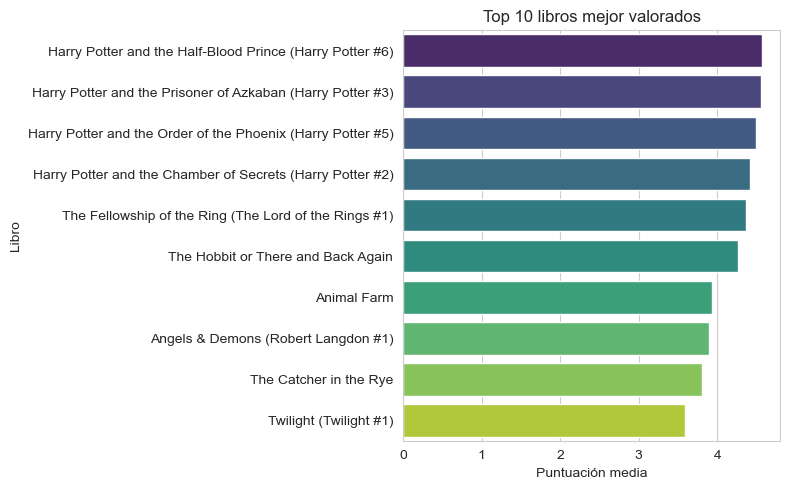

In [11]:
top_ten = df[df['ratings_count'] > 1000000]
top_ten = top_ten.sort_values(by='ratings_count', ascending=False).head(10)
top_ten_rating = top_ten.sort_values(by='average_rating', ascending=False)

plt.figure(figsize=(8, 5))
sns.set_style("whitegrid")

sns.barplot( x="average_rating",y="title",data=top_ten_rating,palette="viridis")

plt.title("Top 10 libros mejor valorados")
plt.xlabel("Puntuación media")
plt.ylabel("Libro")
plt.tight_layout()
plt.show()

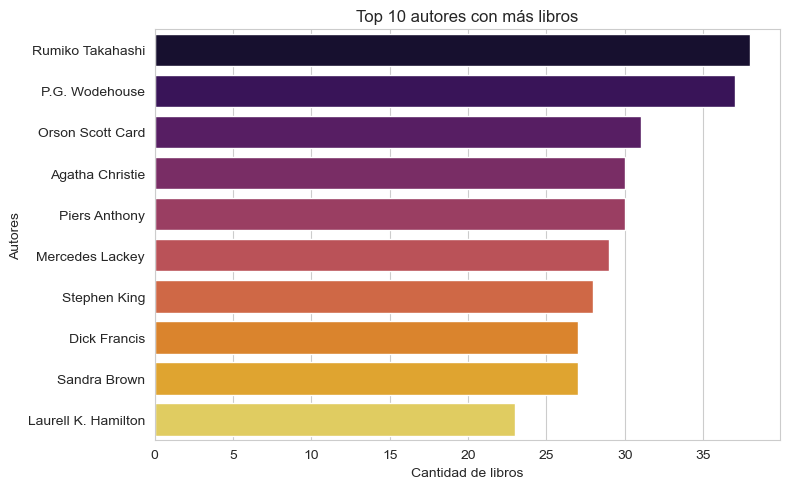

In [12]:
book_aut = df.groupby('authors')['title'].count().nlargest(10)

sns.set_style("whitegrid")
plt.figure(figsize=(8, 5))

sns.barplot(x=book_aut.values, y=book_aut.index, palette="inferno")

plt.title("Top 10 autores con más libros")
plt.xlabel("Cantidad de libros")
plt.ylabel("Autores")
plt.tight_layout()
plt.show()

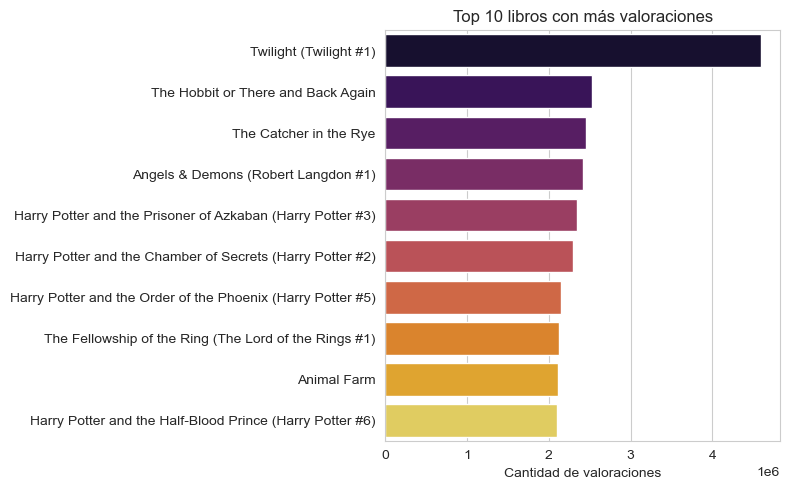

In [13]:
most_rated = df[['title', 'ratings_count']].dropna(subset=['ratings_count']).nlargest(10, 'ratings_count').set_index('title')

sns.set_style("whitegrid")
plt.figure(figsize=(8, 5))

sns.barplot(x=most_rated['ratings_count'], y=most_rated.index, palette="inferno")

plt.title("Top 10 libros con más valoraciones")
plt.xlabel("Cantidad de valoraciones")
plt.ylabel("")
plt.tight_layout()
plt.show()

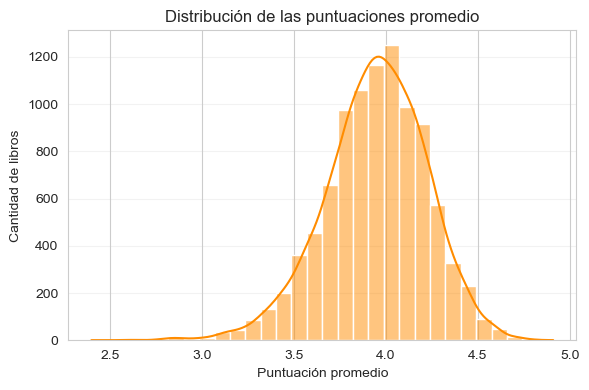

In [14]:
# Ordenar los datos y convertir la puntuación a tipo numérico
df = df.sort_values('average_rating').reset_index(drop=True)
df['average_rating'] = df['average_rating'].astype(float)

# Distribución de las puntuaciones promedio
fig, ax = plt.subplots(figsize=(6, 4))

sns.histplot(data=df,x='average_rating',bins=30,kde=True,ax=ax,color='darkorange')

ax.set_title('Distribución de las puntuaciones promedio',)
ax.set_xlabel('Puntuación promedio')
ax.set_ylabel('Cantidad de libros')
ax.grid(axis='y', alpha=0.25)

plt.tight_layout()
plt.show()

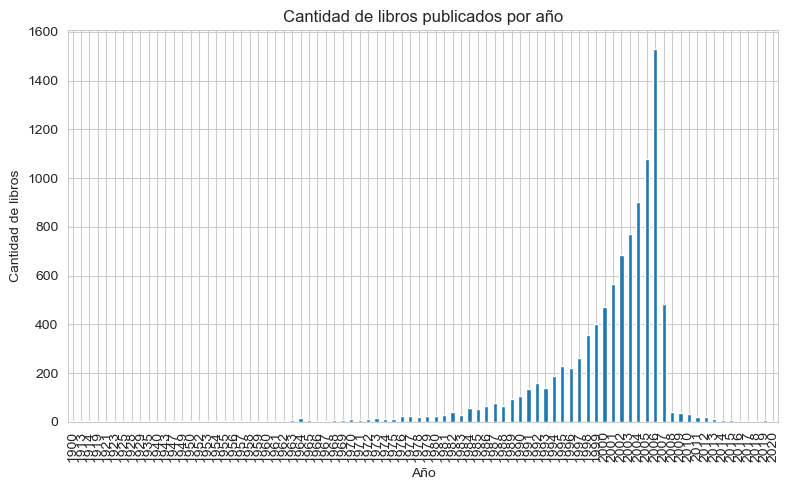

In [15]:
libros_anio = df['anio'].value_counts().sort_index()

libros_anio.plot(kind='bar', figsize=(8, 5))

plt.title('Cantidad de libros publicados por año')
plt.xlabel('Año')
plt.ylabel('Cantidad de libros')
plt.tight_layout()
plt.show()

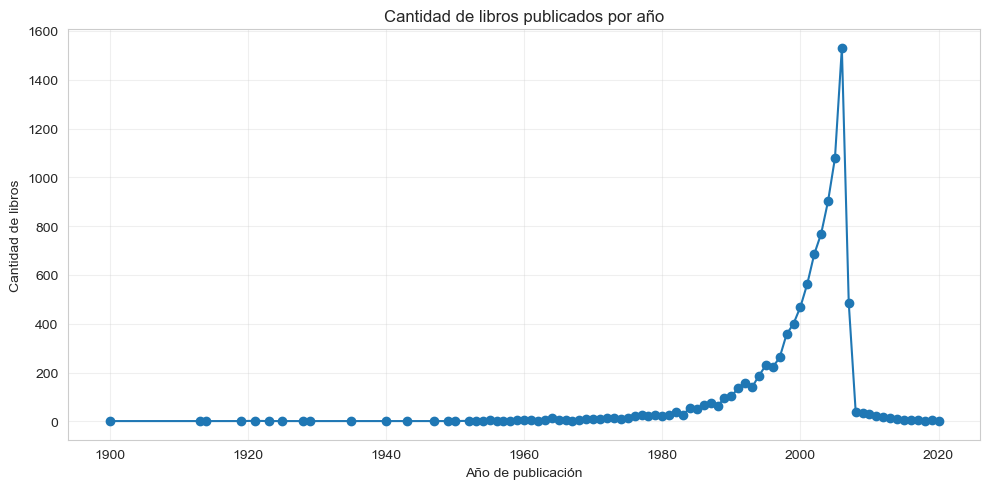

In [16]:
libros_anio = df['anio'].value_counts().sort_index()

plt.figure(figsize=(10, 5))
plt.plot(libros_anio.index, libros_anio.values, marker='o')

plt.title('Cantidad de libros publicados por año')
plt.xlabel('Año de publicación')
plt.ylabel('Cantidad de libros')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


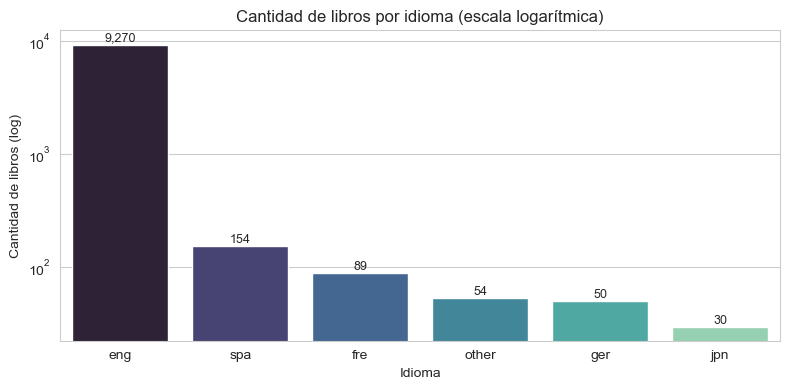

In [17]:
idioma_cnt = df['idioma'].value_counts()

plt.figure(figsize=(8, 4))
sns.set_style("whitegrid")
sns.barplot(x=idioma_cnt.index, y=idioma_cnt.values, palette="mako")
plt.yscale('log')   # escala log: 'eng' domina y taparia al resto

for i, v in enumerate(idioma_cnt.values):
    plt.text(i, v, f"{v:,}", ha='center', va='bottom', fontsize=9)

plt.title('Cantidad de libros por idioma (escala logarítmica)')
plt.xlabel('Idioma')
plt.ylabel('Cantidad de libros (log)')
plt.tight_layout()
plt.show()

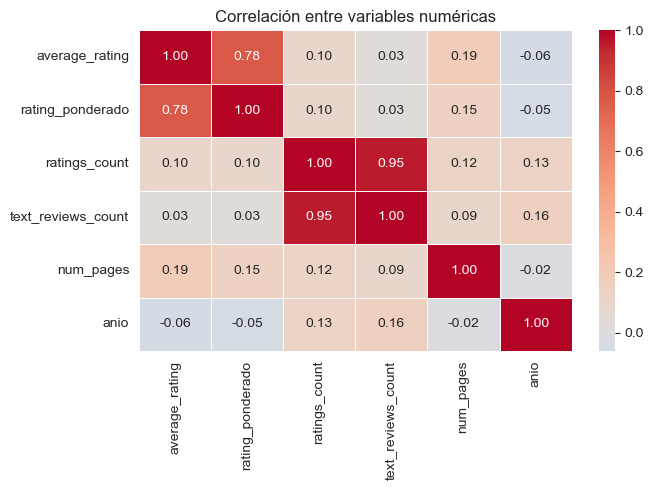

In [18]:
cols_num = ['average_rating', 'rating_ponderado', 'ratings_count', 'text_reviews_count', 'num_pages', 'anio']
df_corr = df[cols_num].copy()
for c in ['ratings_count', 'text_reviews_count']:
    df_corr[c] = np.log1p(df_corr[c])

plt.figure(figsize=(7, 5))
sns.heatmap(df_corr.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title('Correlación entre variables numéricas')
plt.tight_layout()
plt.show()

### Desarrollo & Preprocesamiento

Se arma una representación numérica de cada libro (**content-based**: recomienda libros parecidos a uno dado):

- Variables numéricas: `average_rating`, `rating_ponderado`, `ratings_count`, `text_reviews_count`, `num_pages` y `anio`.
- `ratings_count` y `text_reviews_count` pasan por `log1p`, porque tienen una cola muy larga y sin esto unos pocos best sellers aplastarían a los demas.
- `idioma` se convierte con *one-hot*, así el modelo no recomienda un libro en francés a quien lee en inglés.
- Todo se lleva a la escala 0-1 con `MinMaxScaler`, para que ninguna variable pese más solo por su unidad (por ejemplo, páginas vs. rating).

In [19]:
df2 = df.reset_index(drop=True)   # el indice debe coincidir con la fila de la matriz de features

cols_num = ['average_rating', 'rating_ponderado', 'ratings_count', 'text_reviews_count', 'num_pages', 'anio']
X_raw = df2[cols_num].copy()
for c in ['ratings_count', 'text_reviews_count']:
    X_raw[c] = np.log1p(X_raw[c])

X_raw = pd.concat([X_raw, pd.get_dummies(df2['idioma'], prefix='idioma').astype(float)], axis=1)
feature_cols = X_raw.columns.tolist()

In [20]:
minmax = MinMaxScaler()
feature = minmax.fit_transform(X_raw)

print("Matriz de features:", feature.shape)
print("Columnas:", feature_cols)

Matriz de features: (9647, 12)
Columnas: ['average_rating', 'rating_ponderado', 'ratings_count', 'text_reviews_count', 'num_pages', 'anio', 'idioma_eng', 'idioma_fre', 'idioma_ger', 'idioma_jpn', 'idioma_other', 'idioma_spa']


In [21]:
model = neighbors.NearestNeighbors(n_neighbors=8, algorithm='ball_tree')
model.fit(feature)


NearestNeighbors(algorithm='ball_tree', n_neighbors=8)

In [22]:
dist, idlist = model.kneighbors(feature)

def _norm(texto):
    """Minusculas y espacios simples: 'Prince (Harry Potter  #6)' == 'prince (harry potter #6)'."""
    return " ".join(str(texto).lower().split())

titulos_norm = df2['title'].map(_norm)

def bookRecom(name):
    coincidencias = titulos_norm[titulos_norm == _norm(name)].index
    if len(coincidencias) == 0:
        sugeridos = difflib.get_close_matches(_norm(name), titulos_norm.tolist(), n=3, cutoff=0.5)
        raise ValueError(f"No se encontro '{name}'. Titulos parecidos: {sugeridos}")
    book_id = coincidencias[0]
    book_list = []
    for new in idlist[book_id]:
        if new != book_id:          # se excluye el libro consultado
            book_list.append(df2.loc[new].title)
    return book_list

Ejemplos

In [23]:
Book_name = bookRecom('Harry Potter and the Half-Blood Prince (Harry Potter  #6)')
Book_name

['Harry Potter and the Prisoner of Azkaban (Harry Potter #3)',
 'Harry Potter and the Order of the Phoenix (Harry Potter #5)',
 'The Book Thief',
 'The Fellowship of the Ring (The Lord of the Rings #1)',
 'Harry Potter and the Chamber of Secrets (Harry Potter #2)',
 'Dragonfly in Amber (Outlander #2)',
 'The Princess Bride']

In [24]:
Book_name = bookRecom('The Catcher in the Rye')
Book_name

['The Curious Incident of the Dog in the Night-Time',
 'The Alchemist',
 'Lord of the Flies',
 'Romeo and Juliet',
 'The Adventures of Huckleberry Finn (Adventures of Tom and Huck #2)',
 'Animal Farm',
 'Of Mice and Men']

Metricas del modelo

In [25]:
y = df2['average_rating'].values
X_sin_rating = X_raw.drop(columns=['average_rating', 'rating_ponderado'])

idx_tr, idx_te = train_test_split(np.arange(len(df2)), test_size=0.2, random_state=42)

sc_eval = MinMaxScaler().fit(X_sin_rating.iloc[idx_tr])        # el scaler se ajusta solo con train
Xtr = sc_eval.transform(X_sin_rating.iloc[idx_tr])
Xte = sc_eval.transform(X_sin_rating.iloc[idx_te])
ytr, yte = y[idx_tr], y[idx_te]

def evaluar_k(k):
    nn = neighbors.NearestNeighbors(n_neighbors=k, algorithm='ball_tree').fit(Xtr)
    _, ind = nn.kneighbors(Xte)
    pred = ytr[ind].mean(axis=1)
    return mean_absolute_error(yte, pred), np.sqrt(mean_squared_error(yte, pred)), r2_score(yte, pred)

# Baseline: predecir siempre el promedio del train
pred_base = np.full(len(yte), ytr.mean())
base = (mean_absolute_error(yte, pred_base), np.sqrt(mean_squared_error(yte, pred_base)), r2_score(yte, pred_base))

ks = [1, 3, 5, 8, 10, 15, 20, 30, 50, 100]
res_k = pd.DataFrame([(k, *evaluar_k(k)) for k in ks], columns=['K', 'MAE', 'RMSE', 'R2']).set_index('K')

print("Baseline (promedio global): MAE=%.4f | RMSE=%.4f | R2=%.4f\n" % base)
print("Modelo en uso (K=8):        MAE=%.4f | RMSE=%.4f | R2=%.4f\n" % tuple(res_k.loc[8]))
res_k.round(4)

Baseline (promedio global): MAE=0.2209 | RMSE=0.2857 | R2=-0.0003

Modelo en uso (K=8):        MAE=0.2190 | RMSE=0.2854 | R2=0.0022



,MAE,RMSE,R2
K,,,
1,0.2862,0.3729,-0.7036
3,0.2396,0.3099,-0.1765
5,0.2285,0.2960,-0.0737
8,0.2190,0.2854,0.0022
10,0.2154,0.2813,0.0306
15,0.2137,0.2785,0.0499
20,0.2110,0.2751,0.0727
30,0.2086,0.2714,0.0976
50,0.2080,0.2698,0.1085


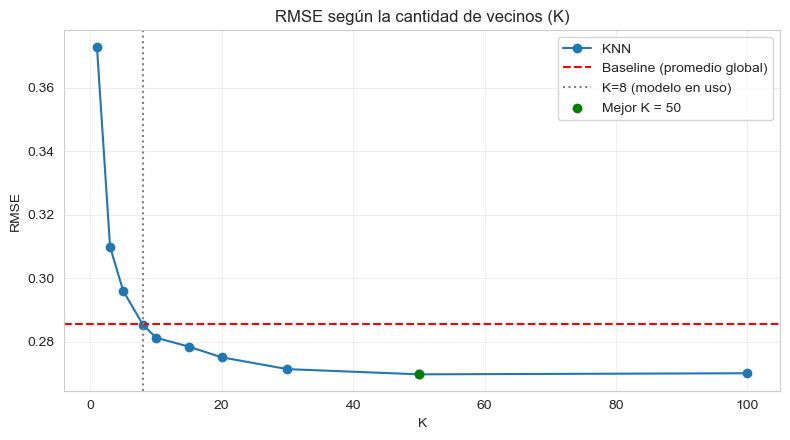

In [26]:
mejor_k = res_k['RMSE'].idxmin()

plt.figure(figsize=(8, 4.5))
plt.plot(res_k.index, res_k['RMSE'], marker='o', label='KNN')
plt.axhline(base[1], color='red', linestyle='--', label='Baseline (promedio global)')
plt.axvline(8, color='gray', linestyle=':', label='K=8 (modelo en uso)')
plt.scatter([mejor_k], [res_k.loc[mejor_k, 'RMSE']], color='green', zorder=5, label=f'Mejor K = {mejor_k}')

plt.title('RMSE según la cantidad de vecinos (K)')
plt.xlabel('K')
plt.ylabel('RMSE')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [27]:
K = 8
N = len(df2)

_, ind = model.kneighbors(feature, n_neighbors=K + 1)
# se quita el propio libro de su lista de vecinos (si hay empates exactos puede no estar en la posicion 0)
vecinos = np.array([[j for j in fila if j != i][:K] for i, fila in enumerate(ind)])

# `serie` se descarto al cargar el dataset (no es feature del modelo); aca se lee aparte solo para evaluar
serie = df2['bookID'].map(pd.read_csv("books_recomendacion.csv", usecols=['bookID', 'serie']).set_index('bookID')['serie'])

aut = pd.factorize(df2['authors'])[0]
ser = pd.factorize(serie)[0]                   # NaN -> -1 (libro sin saga)

relevante = (aut[vecinos] == aut[:, None]) | ((ser[vecinos] == ser[:, None]) & (ser[:, None] >= 0))

# total de libros relevantes que existen para cada consulta (mismo autor o misma saga, sin contarse a si mismo)
n_aut  = df2.groupby('authors')['bookID'].transform('size') - 1
n_ser  = (df2.groupby(serie)['bookID'].transform('size') - 1).fillna(0)
n_both = (df2.groupby([df2['authors'], serie])['bookID'].transform('size') - 1).fillna(0)
tot_rel = (n_aut + n_ser - n_both).values

q = tot_rel > 0                                  # solo consultas que tienen al menos un libro relevante posible
hits = relevante.sum(axis=1)[q]

prec = hits / K
rec  = hits / tot_rel[q]
f1   = np.where(prec + rec > 0, 2 * prec * rec / (prec + rec + 1e-12), 0)

# Referencia: recomendar K libros al azar
prec_azar = (tot_rel[q] / (N - 1)).mean()
rec_azar  = K / (N - 1)
f1_azar   = (2 * (tot_rel[q] / (N - 1)) * rec_azar / ((tot_rel[q] / (N - 1)) + rec_azar)).mean()

metricas_rank = pd.DataFrame({
    'KNN (modelo)': [prec.mean(), rec.mean(), f1.mean(), (hits > 0).mean()],
    'Azar':         [prec_azar, rec_azar, f1_azar, np.nan],
}, index=[f'Precision@{K}', f'Recall@{K}', f'F1@{K}', f'Hit rate@{K}'])
metricas_rank['Mejora (x veces)'] = metricas_rank['KNN (modelo)'] / metricas_rank['Azar']

print(f"Consultas evaluadas: {q.sum():,} de {N:,} (libros con al menos un libro del mismo autor o saga)")
metricas_rank.round(4)

Consultas evaluadas: 5,141 de 9,647 (libros con al menos un libro del mismo autor o saga)


,KNN (modelo),Azar,Mejora (x veces)
Precision@8,0.0517,0.0007,73.2868
Recall@8,0.0702,0.0008,84.6039
F1@8,0.0485,0.0006,79.2110
Hit rate@8,0.2237,NaN,NaN


##### Guardado Modelo

In [28]:
modelo_final = {
    'scaler': minmax,
    'model': model,
    'X_scaled': feature,
    'feature_cols': feature_cols,
    'catalogo': df2[['bookID', 'title', 'authors', 'average_rating', 'ratings_count', 'num_pages', 'anio', 'idioma']].copy(),
    'n_neighbors': 8,
    'sklearn_version': sklearn.__version__,
}

joblib.dump(modelo_final, 'modelo_knn_libros.joblib', compress=3)
print("Modelo guardado: modelo_knn_libros.joblib (%.2f MB)" % (os.path.getsize('modelo_knn_libros.joblib') / 1e6))

Modelo guardado: modelo_knn_libros.joblib (1.07 MB)


Comprobacion del modelo

In [29]:
def recomendar(titulo, modelo, n=5):
    """Devuelve los n libros mas parecidos a `titulo` usando el modelo guardado."""
    cat = modelo['catalogo']
    norm = cat['title'].map(_norm)
    q = _norm(titulo)

    cand = cat[norm == q]                                   # 1) coincidencia exacta
    if cand.empty:
        cand = cat[norm.str.contains(re.escape(q))]         # 2) coincidencia parcial
    if cand.empty:
        sug = difflib.get_close_matches(q, norm.tolist(), n=3, cutoff=0.5)
        print(f"No se encontro '{titulo}'. Titulos parecidos: {[cat.loc[norm == s, 'title'].iloc[0] for s in sug]}")
        return None

    i = cand['ratings_count'].idxmax()                      # si hay varias ediciones, la mas valorada
    dist, ind = modelo['model'].kneighbors(modelo['X_scaled'][i:i + 1], n_neighbors=n + 15)

    elegidos, vistos = [], {norm[i]}                        # se evita repetir el libro u otras ediciones del mismo titulo
    for d, j in zip(dist[0], ind[0]):
        if norm[j] in vistos:
            continue
        vistos.add(norm[j])
        elegidos.append((j, d))
        if len(elegidos) == n:
            break

    out = cat.loc[[j for j, _ in elegidos], ['title', 'authors', 'average_rating', 'anio', 'idioma']].copy()
    out.insert(0, 'distancia', [round(d, 3) for _, d in elegidos])
    out.index = range(1, len(out) + 1)
    print(f"Libro consultado: {cat.loc[i, 'title']}  |  {cat.loc[i, 'authors']}  |  rating {cat.loc[i, 'average_rating']}")
    return out

Carga del Modelo & Examenes Finales

In [30]:
modelo_cargado = joblib.load('modelo_knn_libros.joblib')

# Control: el modelo cargado debe dar exactamente lo mismo que el que esta en memoria
d1, i1 = modelo_final['model'].kneighbors(modelo_final['X_scaled'][:50])
d2, i2 = modelo_cargado['model'].kneighbors(modelo_cargado['X_scaled'][:50])
assert (i1 == i2).all() and np.allclose(d1, d2)
print("OK: el modelo cargado reproduce exactamente los resultados del original\n")

recomendar('Harry Potter and the Half-Blood Prince (Harry Potter  #6)', modelo_cargado, n=5)

OK: el modelo cargado reproduce exactamente los resultados del original

Libro consultado: Harry Potter and the Half-Blood Prince (Harry Potter #6)  |  J.K. Rowling/Mary GrandPré  |  rating 4.57


,distancia,title,authors,average_rating,anio,idioma
1,0.165,Harry Potter and the Prisoner of Azkaban (Harr...,J.K. Rowling/Mary GrandPré,4.56,2004,eng
2,0.171,Harry Potter and the Order of the Phoenix (Har...,J.K. Rowling/Mary GrandPré,4.49,2004,eng
3,0.177,The Book Thief,Markus Zusak/Cao Xuân Việt Khương,4.37,2006,eng
4,0.239,The Fellowship of the Ring (The Lord of the Ri...,J.R.R. Tolkien,4.36,2003,eng
5,0.257,Harry Potter and the Chamber of Secrets (Harry...,J.K. Rowling/Mary GrandPré,4.42,1999,eng


In [31]:
recomendar('Twilight (Twilight #1)', modelo_cargado, n=5)

Libro consultado: Twilight (Twilight #1)  |  Stephenie Meyer  |  rating 3.59


,distancia,title,authors,average_rating,anio,idioma
1,0.151,Eat Pray Love,Elizabeth Gilbert,3.55,2007,eng
2,0.192,The Da Vinci Code (Robert Langdon #2),Dan Brown,3.84,2006,eng
3,0.223,Romeo and Juliet,William Shakespeare/Paul Werstine/Barbara A. M...,3.74,2004,eng
4,0.231,The Catcher in the Rye,J.D. Salinger,3.80,2001,eng
5,0.239,The Memory Keeper's Daughter,Kim Edwards,3.67,2006,eng


In [32]:
recomendar('The Hobbit or There and Back Again', modelo_cargado, n=5)

Libro consultado: The Hobbit or There and Back Again  |  J.R.R. Tolkien  |  rating 4.27


,distancia,title,authors,average_rating,anio,idioma
1,0.056,The Lightning Thief (Percy Jackson and the Oly...,Rick Riordan,4.25,2006,eng
2,0.098,Harry Potter and the Chamber of Secrets (Harry...,J.K. Rowling/Mary GrandPré,4.42,1999,eng
3,0.099,The Fellowship of the Ring (The Lord of the Ri...,J.R.R. Tolkien,4.36,2003,eng
4,0.115,The Glass Castle,Jeannette Walls,4.27,2006,eng
5,0.133,Memoirs of a Geisha,Arthur Golden,4.11,2005,eng


In [33]:
recomendar('Cien años de soledad', modelo_cargado, n=5)

Libro consultado: Cien años de soledad  |  Gabriel García Márquez  |  rating 4.07


,distancia,title,authors,average_rating,anio,idioma
1,0.059,No me cogeréis vivo: artículos 2001-2005,Arturo Pérez-Reverte,4.16,2005,spa
2,0.071,El rey de Les Halles,Juliette Benzoni/Francisco Rodriguez de Lecea,4.19,2007,spa
3,0.079,La conspiración de los alquimistas,Hania Czajkowski,4.00,2005,spa
4,0.088,La Torre Oscura VII - Tomo 2 of 2 (La Torre Os...,Stephen King/Verónica Canales,4.24,2006,spa
5,0.091,La conjura de los necios,John Kennedy Toole,3.89,2006,spa


In [34]:
# Ejemplo que no esta en el dataset
recomendar('Gone Girl', modelo_cargado, n=5)

No se encontro 'Gone Girl'. Titulos parecidos: ['Clown Girl', 'Nature Girl', 'The Orange Girl']


### Conclusion Final

El modelo en uso es un **KNN content-based** (`NearestNeighbors`, `ball_tree`, distancia euclidiana, `K=8`). No tiene una "respuesta correcta" directa, así que se evalua desde dos ángulos que corresponden a la tabla de métricas del inicio:

1. **Predicción de calificación (MAE, RMSE, R2):** se separa 80% train / 20% test. Para cada libro de test se buscan sus K vecinos *dentro del train* y se predice su `average_rating` como el promedio de los vecinos. Para evitar *data leakage* en esta prueba se **excluyen** `average_rating` y `rating_ponderado` de las features. Se compara contra un baseline que siempre predice el promedio global.
2. **Calidad del ranking (Precision@K, Recall@K, F1@K):** un libro recomendado se considera *relevante* si comparte **autor o saga** con el libro consultado. Ni el autor ni la saga son features del modelo, así que es una prueba independiente de si el espacio de features agrupa libros realmente relacionados. Se compara contra recomendar libros al azar.

**Predicción de calificación (MAE / RMSE / R²)**

- Con `K=8` el modelo obtiene MAE 0.211 y RMSE 0.278, contra 0.221 y 0.286 del baseline. Mejora, pero poco (R² = 0.05).
- Al subir K el error baja y se estabiliza cerca de `K=50` (MAE 0.205, RMSE 0.267, R² 0.13). Con K muy chico (1 a 3) el modelo es **peor que el baseline**: es la sensibilidad a K que se describe al inicio de la notebook.
- Que el R² sea bajo es esperable: se predice la calificación sin conocer género, trama ni autor; solo popularidad, páginas, año e idioma.

**Calidad del ranking (Precision / Recall / F1 @8)**

- Precision@8 = 5.2%, Recall@8 = 7.0% y F1@8 = 4.9%. En 22% de las consultas aparece al menos un libro del mismo autor o saga entre las 8 recomendaciones (Hit rate).
- Son entre **73 y 85 veces mejores que recomendar al azar** (~0.07%), aunque en valores absolutos son bajos: el criterio es estricto y el modelo no conoce el autor.
- El Recall tiene un techo bajo por construcción: hay autores con decenas de libros y la lista tiene solo 8 lugares.

**Sobre K:** para la lista de recomendaciones se mantiene `K=8` (una lista corta y útil). Un K mayor mejora el error de predicción, pero no tiene sentido para recomendar.

---

**Qué se hizo.** Se construyó un sistema de recomendación **content-based con KNN** (`NearestNeighbors`, `ball_tree`, `K=8`) sobre 9.647 libros. Cada libro se representa con su calificación, popularidad (en escala log), páginas, año e idioma, todo normalizado con `MinMaxScaler`. El modelo final quedó guardado en `modelo_knn_libros.joblib`, se volvió a cargar desde el archivo y se probó con cinco casos, incluido un título inexistente que se maneja sin romperse.

**Qué mostraron las visualizaciones**

- **Top 10 mejor valorados y más valorados:** la lista la dominan Harry Potter y El Señor de los Anillos (~4.3 a 4.6); *Twilight* es el libro con más valoraciones (más de 4,5 millones) pero con la calificación más baja del grupo (~3.6). Popularidad y calidad percibida **no son lo mismo**, y por eso el modelo usa ambas como variables separadas.
- **Distribución de puntuaciones:** casi normal y centrada en ~4.0, con la gran mayoría entre 3.5 y 4.5. Los libros se diferencian por poco, lo que explica por qué predecir la calificación es difícil (R² bajo).
- **Libros por año:** crecen de forma sostenida hasta un pico en 2006 (~1.500 libros) y caen en seco después. El dataset está concentrado entre 2000 y 2006, así que el modelo conoce mejor ese período.
- **Libros por idioma:** 9.270 de 9.647 son en inglés (96%). Por eso `idioma` entra como variable: así los libros en español se recomiendan entre sí (como se vio en la prueba con *Cien años de soledad*), aunque con un catálogo muy chico.
- **Correlaciones:** `ratings_count` y `text_reviews_count` están casi duplicadas (0.95) y `average_rating` con `rating_ponderado` también (0.78), mientras que el resto de las variables casi no se relacionan entre sí. Por eso el espacio de features aporta información distinta y no es redundante, salvo esos dos pares.
- **Curva de K:** el error cae rápido hasta K≈20 y casi no mejora después de K=50; K=1 a 3 queda peor que el baseline.
- **Top autores:** Rumiko Takahashi (38) y P.G. Wodehouse (37) lideran en cantidad de libros; ningún autor concentra una parte grande del catálogo.

**Qué dicen las métricas.** El modelo supera claramente al azar (73 a 85 veces mejor en Precision/Recall/F1@8) y mejora el baseline en predicción de calificación, aunque con valores absolutos modestos (MAE 0.211, RMSE 0.278, R² 0.05 con K=8).

**Limitaciones**

- No usa género, descripción ni autor, por lo que recomienda libros "parecidos en perfil" (popularidad, calificación, época), no necesariamente del mismo tema. Por ejemplo, para *Twilight* sugiere *Eat Pray Love* o *El Código Da Vinci*, que comparten perfil pero no género.
- No hay datos de usuarios, así que no es personalizado: es un recomendador "si te gustó este libro".
- Sesgo hacia el inglés y hacia 2000-2006, y las métricas de ranking usan autor/saga como proxy de relevancia, que es una aproximación.

**Próximos pasos.** Sumar texto (género, descripción o TF-IDF del título) como feature, probar similitud del coseno con `algorithm='brute'` y, si se consiguen calificaciones por usuario, pasar a un enfoque colaborativo (user-based o item-based).